In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# --- load (given) ---
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("raw shapes:", x_train.shape, y_train.shape)

# Q1a) Normalise pixels to [0, 1]
PIXEL_MAX = None            # TODO (Q1a): the largest pixel value
x_train = x_train / 255
x_test  = x_test  / 255

# Q1b) Reshape to (samples, time_steps, features). Fill time_steps and features.
TIME_STEPS = 28          # TODO (Q1b): number of rows read as time steps
FEATURES   = 28          # TODO (Q1b): number of pixels per row
x_train = x_train.reshape((x_train.shape[0], TIME_STEPS, FEATURES))
x_test  = x_test.reshape((x_test.shape[0],  TIME_STEPS, FEATURES))

# Q1c) One-hot encode the labels
NUM_CLASSES = None         # TODO (Q1c): number of digit classes
y_train = to_categorical(y_train, NUM_CLASSES)
y_test  = to_categorical(y_test,  NUM_CLASSES)

print("prepared:", x_train.shape, y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
raw shapes: (60000, 28, 28) (60000,)
prepared: (60000, 28, 28) (60000, 10)


In [3]:
assert x_train.max() <= 1.0 and x_train.min() >= 0.0, "pixels not in [0,1]"
assert x_train.shape[1:] == (28, 28), "sequence shape should be (28, 28)"
assert y_train.shape[1] == 10, "labels should be one-hot with 10 columns"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [5]:
model = models.Sequential()

# Q2a) LSTM layer: fill the number of units and the input_shape
LSTM_UNITS = 64          # TODO (Q2a): number of LSTM memory units
model.add(layers.LSTM(LSTM_UNITS,
                      activation='relu',
                      input_shape=(TIME_STEPS, FEATURES)))   # TODO (Q2a): (time_steps, features)

# Q2b) Output layer: one neuron per class, softmax activation
OUT_UNITS = 10           # TODO (Q2b): number of output neurons
model.add(layers.Dense(OUT_UNITS, activation='softmax'))   # TODO (Q2b): activation name as a string

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        23,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,458 (95.54 KB)

 Trainable params: 24,458 (95.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Q3a) Compile — fill optimiser, loss, and metric
model.compile(optimizer='adam',        # TODO (Q3a): optimiser name as a string
              loss='categorical_crossentropy',             # TODO (Q3a): loss name as a string
              metrics=['accuracy'])        # TODO (Q3a): metric name as a string

# Q3b) Train — fill epochs and batch_size
history = model.fit(x_train, y_train,
                    epochs=5,              # TODO (Q3b)
                    batch_size=128,          # TODO (Q3b)
                    validation_data=(x_test, y_test))

# Q3c) Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - accuracy: 0.7614 - loss: 0.7247 - val_accuracy: 0.9155 - val_loss: 0.2728
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.9343 - loss: 0.2157 - val_accuracy: 0.9507 - val_loss: 0.1623
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9526 - loss: 0.1511 - val_accuracy: 0.9584 - val_loss: 0.1265
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9615 - loss: 0.1239 - val_accuracy: 0.9684 - val_loss: 0.0962
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9695 - loss: 0.0986 - val_accuracy: 0.9714 - val_loss: 0.0897
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9714 - loss: 0.0897
Test accuracy: 97.14%


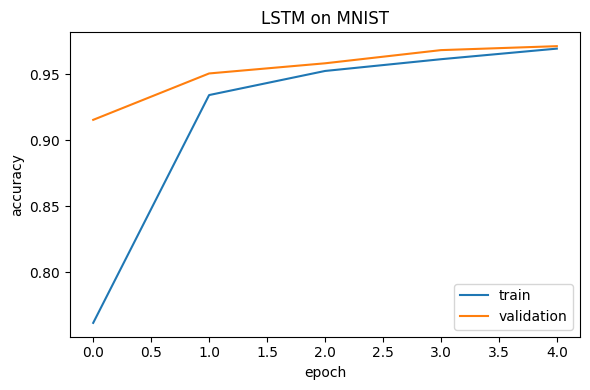

In [9]:
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'],     label='train')
plt.plot(history.history['val_accuracy'], label='validation')   # TODO (Q4): which key holds val accuracy?
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.title('LSTM on MNIST')
plt.tight_layout(); plt.show()